In [1]:
import pandas as pd

train = pd.read_csv("data/train.csv")
print(train.shape)
print(train.head())

(4500, 73)
   project_id  num_commits  active_commit_days  project_span_days  \
0  535ce026f7           44                  15                 56   
1  869ba41ed7            9                   3                 76   
2  d6f81f8862           12                   1                  0   
3  152b5d915d            4                   1                  0   
4  3b5f8a49e6            7                   3                 64   

  commit_cadence  pct_commits_weekend  pct_commits_late_night  \
0          daily               0.2045                  0.4545   
1       sporadic               0.8889                  0.0000   
2       frequent               1.0000                  0.0000   
3       frequent               0.0000                  0.2500   
4       sporadic               0.8571                  0.0000   

   lines_added_total  lines_deleted_total  churn_ratio  ...  forks  \
0               8500                 2900       0.3438  ...      0   
1                500                  100  

In [2]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 73 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   project_id                       4500 non-null   str    
 1   num_commits                      4500 non-null   int64  
 2   active_commit_days               4500 non-null   int64  
 3   project_span_days                4500 non-null   int64  
 4   commit_cadence                   4500 non-null   str    
 5   pct_commits_weekend              4500 non-null   float64
 6   pct_commits_late_night           4500 non-null   float64
 7   lines_added_total                4500 non-null   int64  
 8   lines_deleted_total              4500 non-null   int64  
 9   churn_ratio                      4479 non-null   float64
 10  median_lines_per_commit          4500 non-null   float64
 11  max_lines_in_one_commit          4500 non-null   int64  
 12  pct_code_in_first_commit       

count    4500.000000
mean       12.136178
std        19.047682
min         0.100000
25%         2.700000
50%         6.000000
75%        12.900000
max       140.700000
Name: hours_spent, dtype: float64


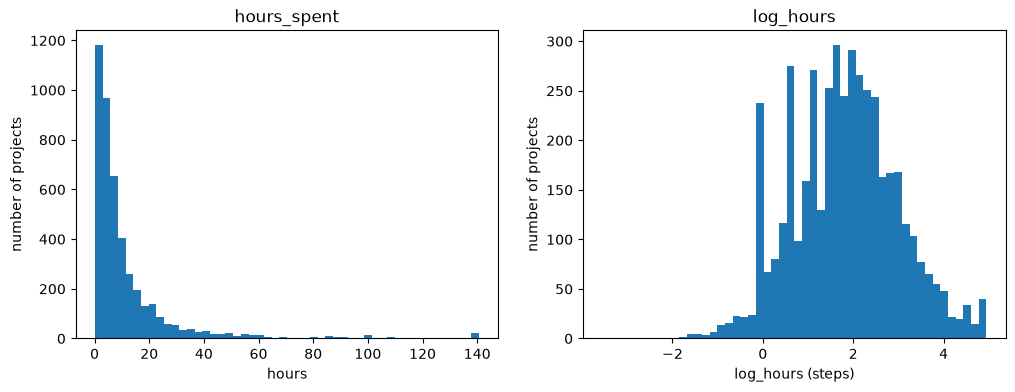

   hours_spent  log_hours
0         32.2     3.4726
1          5.0     1.6094
2          1.3     0.2624
3          2.0     0.6931
4          4.0     1.3863
0    3.471966
1    1.609438
2    0.262364
3    0.693147
4    1.386294
Name: hours_spent, dtype: float64
0    3.502550
1    1.791759
2    0.832909
3    1.098612
4    1.609438
Name: hours_spent, dtype: float64


In [5]:
import numpy as np
import matplotlib.pyplot as plt

print(train["hours_spent"].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train["hours_spent"], bins=50)
ax[0].set_title("hours_spent")
ax[1].hist(train["log_hours"], bins=50)
ax[1].set_title("log_hours")
ax[0].set_xlabel("hours")
ax[0].set_ylabel("number of projects")
ax[1].set_xlabel("log_hours (steps)")
ax[1].set_ylabel("number of projects")
plt.show()

# Is log_hours a plain log or log1p?
print(train[["hours_spent", "log_hours"]].head())
print(np.log(train["hours_spent"]).head())
print(np.log1p(train["hours_spent"]).head())

# log_hours = np.log(hours_spent)  ->  convert back with np.exp()

In [4]:
missing = train.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

is_mobile_responsive        1423
num_internal_pages          1423
num_js_files_loaded         1423
load_time_ms                1349
page_weight_kb              1349
avg_file_length              194
pct_primary_language         194
comment_line_ratio           194
pct_code_in_first_commit     186
churn_ratio                   21
project_category               5
is_clone_or_tutorial           5
is_multiplayer                 5
mentions_ai_api                3
has_custom_art                 2
dtype: int64


In [6]:
for col in train.select_dtypes(include="object").columns:
    print(col)
    print(train[col].value_counts().head(10))
    print()

project_id
project_id
535ce026f7    1
869ba41ed7    1
d6f81f8862    1
152b5d915d    1
3b5f8a49e6    1
4de0b46357    1
8dc183691e    1
6e2b490204    1
dbed5bd8d3    1
ef2d716335    1
Name: count, dtype: int64

commit_cadence
commit_cadence
frequent    2561
sporadic     992
daily        947
Name: count, dtype: int64

primary_language
primary_language
JavaScript    940
HTML          587
CSS           532
GDScript      518
Python        502
TypeScript    411
none          194
Rust          109
Java          102
C#             86
Name: count, dtype: int64

framework
framework
none         2472
godot         658
nextjs        195
other         194
react         189
unity          97
gamemaker      83
astro          82
flask          81
sveltekit      75
Name: count, dtype: int64

has_custom_art
has_custom_art
True     2356
False    2142
Name: count, dtype: int64

hosting_type
hosting_type
itch                1088
github-pages        1032
custom               689
github-repo          509
verc

C:\Users\Fujitsu\AppData\Local\Temp\ipykernel_14052\3196403635.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in train.select_dtypes(include="object").columns:


In [8]:
corr = train.select_dtypes(include="number").corr()["log_hours"]
print(corr.drop(["log_hours", "hours_spent"]).sort_values(ascending=False))

max_dir_depth               0.374600
churn_ratio                 0.273892
readme_word_count           0.260978
avg_commit_msg_length       0.255817
readme_num_headings         0.240292
readme_num_images           0.235179
description_word_count      0.202063
num_languages               0.169524
lines_of_code               0.162354
stars                       0.157017
active_commit_days          0.155072
num_source_files            0.154782
num_dependencies            0.148173
readme_num_code_blocks      0.143282
project_span_days           0.139402
num_releases                0.133194
num_directories             0.128593
load_time_ms                0.119411
num_internal_pages          0.108120
asset_size_mb               0.107642
num_js_files_loaded         0.107044
num_commits                 0.103739
num_font_files              0.094700
lines_added_total           0.093299
comment_line_ratio          0.082160
num_audio_files             0.076704
max_lines_in_one_commit     0.072880
l

In [9]:
corr_s = train.select_dtypes(include="number").corr(method="spearman")["log_hours"]
print(corr_s.drop(["log_hours", "hours_spent"]).sort_values(ascending=False).head(15))

active_commit_days         0.560902
lines_added_total          0.531898
lines_of_code              0.531447
lines_deleted_total        0.529723
num_commits                0.509138
num_source_files           0.495684
num_directories            0.432743
project_span_days          0.430117
max_dir_depth              0.410821
max_lines_in_one_commit    0.398305
readme_word_count          0.366931
churn_ratio                0.328906
avg_commit_msg_length      0.314327
readme_num_headings        0.309349
num_image_files            0.262706
Name: log_hours, dtype: float64
